In [1]:
import sympy as sp
sp.init_printing(use_unicode=True)

In [2]:
c = sp.symbols('c')
u3 = sp.symbols('u3')
u4 = sp.symbols('u4')
u5 = sp.symbols('u5')

In [3]:
# u0 = 1
# u1 = 0
# u2 = 1
u0 = sp.symbols('u0')
u1 = sp.symbols('u1')
u2 = sp.symbols('u2')

In [4]:
sigma00 = u0
sigma01 = u1
sigma11 = u2 - u1**2/u0
sigma12 = u3 - u2*u1/u0
sigma22 = u4 - (sp.Matrix([u2, u3]).T * sp.Matrix([[u0, u1], [u1, u2]]).inv() * sp.Matrix([u2, u3]))[0]
sigma23 = u5 - (sp.Matrix([u3, u4]).T * sp.Matrix([[u0, u1], [u1, u2]]).inv() * sp.Matrix([u2, u3]))[0]

In [8]:
u35 = sp.Matrix([u3, u4, u5])
G2_inv = sp.Matrix([[u0, u1, u2], [u1, u2, u3], [u2, u3, u4]]).inv()
u23 = sp.Matrix([u2, u3])
G1_inv = sp.Matrix([[u0, u1], [u1, u2]]).inv()
beta1 = sigma11 / sigma00
beta2 = sigma22 / sigma11
alpha2_m_alpha0 = (sigma23 / sigma22 - sigma12 / sigma11) - (sigma01 / sigma00)
alpha2_m_alpha1 = (sigma23 / sigma22 - sigma12 / sigma11) - (sigma12 / sigma11 - sigma01 / sigma00)

u6 = (u35.T * G2_inv * u35)[0] + (u4 - (u23.T * G1_inv * u23)[0]) * (beta1 + beta2 + sp.Rational(1, 2) * (alpha2_m_alpha0**2 + alpha2_m_alpha1**2))
u6 = sp.simplify(u6)
u6
print(u6)

(u0**2*(u0*u2 - u1**2)**3*(u2*(u1*u3 - u2**2) - u3*(u0*u3 - u1*u2) + u4*(u0*u2 - u1**2))*(-u3*(u3*(u2*u4 - u3**2) - u4*(u1*u4 - u2*u3) + u5*(u1*u3 - u2**2)) + u4*(u3*(u1*u4 - u2*u3) - u4*(u0*u4 - u2**2) + u5*(u0*u3 - u1*u2)) - u5*(u3*(u1*u3 - u2**2) - u4*(u0*u3 - u1*u2) + u5*(u0*u2 - u1**2))) + (2*u0**3*(u2*(u1*u3 - u2**2) - u3*(u0*u3 - u1*u2) + u4*(u0*u2 - u1**2))**3 + 2*(u0*u2 - u1**2)**3*(u2*(u1*u3 - u2**2) - u3*(u0*u3 - u1*u2) + u4*(u0*u2 - u1**2))**2 + (u0*(u0*u2 - u1**2)*(-u2*(u1*u4 - u2*u3) + u3*(u0*u4 - u1*u3) - u5*(u0*u2 - u1**2)) + u0*(u0*u3 - u1*u2)*(u2*(u1*u3 - u2**2) - u3*(u0*u3 - u1*u2) + u4*(u0*u2 - u1**2)) + u1*(u0*u2 - u1**2)*(u2*(u1*u3 - u2**2) - u3*(u0*u3 - u1*u2) + u4*(u0*u2 - u1**2)))**2 + (u0*(u0*u2 - u1**2)*(u2*(u1*u4 - u2*u3) - u3*(u0*u4 - u1*u3) + u5*(u0*u2 - u1**2)) + 2*u0*(-u0*u3 + u1*u2)*(u2*(u1*u3 - u2**2) - u3*(u0*u3 - u1*u2) + u4*(u0*u2 - u1**2)) + u1*(u0*u2 - u1**2)*(u2*(u1*u3 - u2**2) - u3*(u0*u3 - u1*u2) + u4*(u0*u2 - u1**2)))**2)*(-u0*u2*u4 + u0*u3**2

In [6]:
u6_u0 = sp.diff(u6, u0)
u6_u1 = sp.diff(u6, u1)
u6_u2 = sp.diff(u6, u2)
u6_u3 = sp.diff(u6, u3)
u6_u4 = sp.diff(u6, u4)
u6_u5 = sp.diff(u6, u5)

u6_u0, u6_u1, u6_u2, u6_u3, u6_u4, u6_u5

⎛       ⎛                                                                      ↪
⎜       ⎜                 3                                                    ↪
⎜       ⎜  2 ⎛          2⎞  ⎛   ⎛          2⎞                           ⎛      ↪
⎜  3⋅u₂⋅⎜u₀ ⋅⎝u₀⋅u₂ - u₁ ⎠ ⋅⎝u₂⋅⎝u₁⋅u₃ - u₂ ⎠ - u₃⋅(u₀⋅u₃ - u₁⋅u₂) + u₄⋅⎝u₀⋅u₂ ↪
⎜       ⎝                                                                      ↪
⎜- ─────────────────────────────────────────────────────────────────────────── ↪
⎜                                                                              ↪
⎜                                                                              ↪
⎝                                                                              ↪

↪                                                                              ↪
↪                                                                              ↪
↪      2⎞⎞ ⎛     ⎛   ⎛          2⎞                           ⎛          2⎞⎞    ↪
↪  - u₁ ⎠⎠⋅⎝- u₃⋅⎝u₃⋅⎝u₂⋅u₄

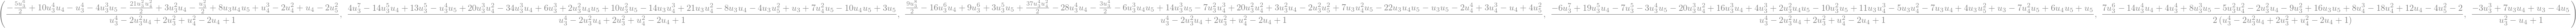

In [7]:
# Insert u0=1, u1=0, u2=1 into the above derivatives to simplify them further
u6_u0_subs = sp.simplify(u6_u0.subs({u0: 1, u1: 0, u2: 1}))
u6_u1_subs = sp.simplify(u6_u1.subs({u0: 1, u1: 0, u2: 1}))
u6_u2_subs = sp.simplify(u6_u2.subs({u0: 1, u1: 0, u2: 1}))
u6_u3_subs = sp.simplify(u6_u3.subs({u0: 1, u1: 0, u2: 1}))
u6_u4_subs = sp.simplify(u6_u4.subs({u0: 1, u1: 0, u2: 1}))
u6_u5_subs = sp.simplify(u6_u5.subs({u0: 1, u1: 0, u2: 1}))
u6_u0_subs, u6_u1_subs, u6_u2_subs, u6_u3_subs, u6_u4_subs, u6_u5_subs

In [18]:
beta3 = beta1 + beta2 + sp.Rational(1, 2) * (alpha2_m_alpha0**2 + alpha2_m_alpha1**2)

In [19]:
alpha0 = 0
alpha1 = u3
alpha2 = sp.simplify((sigma23/sigma22 - sigma12/sigma11).subs({u0: 1, u1: 0, u2: 1}))

In [20]:
alpha3_hat, alpha4_hat, alpha5_hat, beta4_hat, beta5_hat = sp.symbols('alpha3_hat alpha4_hat alpha5_hat beta4_hat beta5_hat')

In [21]:
p1 = c
p2 = c**2 - u3*c - 1
p3_hat = (c - alpha2) * p2 - beta2 * p1
p4_hat = (c - alpha3_hat) * p3_hat - beta3 * p2
p5_hat = (c - alpha4_hat) * p4_hat - beta4_hat * p3_hat
p6_hat = (c - alpha5_hat) * p5_hat - beta5_hat * p4_hat

ansatz = sp.expand(p6_hat)
ansatz = sp.expand(sp.simplify(ansatz.subs({u0: 1, u1: 0, u2: 1})))
ansatz

                                                 3   6                         ↪
                           α₃ ₕₐₜ⋅α₄ ₕₐₜ⋅α₅ ₕₐₜ⋅c ⋅u₃                          ↪
- ──────────────────────────────────────────────────────────────────────────── ↪
    6       4          4       2   2       2          2     3       2          ↪
  u₃  - 3⋅u₃ ⋅u₄ + 3⋅u₃  + 3⋅u₃ ⋅u₄  - 6⋅u₃ ⋅u₄ + 3⋅u₃  - u₄  + 3⋅u₄  - 3⋅u₄ + ↪

↪                                                     3   4                    ↪
↪                             3⋅α₃ ₕₐₜ⋅α₄ ₕₐₜ⋅α₅ ₕₐₜ⋅c ⋅u₃ ⋅u₄                 ↪
↪ ── + ─────────────────────────────────────────────────────────────────────── ↪
↪        6       4          4       2   2       2          2     3       2     ↪
↪  1   u₃  - 3⋅u₃ ⋅u₄ + 3⋅u₃  + 3⋅u₃ ⋅u₄  - 6⋅u₃ ⋅u₄ + 3⋅u₃  - u₄  + 3⋅u₄  - 3 ↪

↪                                                           3   4              ↪
↪                                   3⋅α₃ ₕₐₜ⋅α₄ ₕₐₜ⋅α₅ ₕₐₜ⋅c ⋅u₃               ↪
↪ ─────── - ──────────────

In [22]:
A = ansatz.coeff(c, 5)
B = ansatz.coeff(c, 4)
C = ansatz.coeff(c, 3)
D = ansatz.coeff(c, 2)
E = ansatz.coeff(c, 1)
F = ansatz.coeff(c, 0)

equations = [
    sp.Eq(A, -u6_u5_subs),
    sp.Eq(B, -u6_u4_subs),
    sp.Eq(C, -u6_u3_subs),
    sp.Eq(D, -u6_u2_subs),
    sp.Eq(E, -u6_u1_subs),
    sp.Eq(F, -u6_u0_subs)
]


A, B, C, D, E, F

In [ ]:
# 6 equations, 5 unknowns (alpha3_hat, alpha4_hat, alpha5_hat, beta4_hat, beta5_hat)
sol = sp.solve(equations, (alpha3_hat, alpha4_hat, alpha5_hat, beta4_hat, beta5_hat), dict=True)[0]
# print({k: sp.factor(v) for k, v in sol.items()})
# print(sp.simplify(equations[5].lhs.subs(sol) - u6_u0_subs) == 0)
sol